# Flux post-processing chain: IRGA72 latent heat flux (2016-2026.09)

**notebook version**: `1` (26 Oct 2026). Built from the CO2-flux notebook of this folder
(`05_FPPC_IRGA72_NEE_2016-2026.09`), which is adapted from the diive notebook
`FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

Processes a latent heat flux with the [diive flux post-processing chain](https://diive.readthedocs.io/en/latest/flux_postprocessing.html): outliers (L3.2),
gap-filling (L4.1) and the conversion to evapotranspiration (ET). As in FLUXNET2015 and ONEFlux
(Pastorello et al. 2020), LE gets no storage term (L3.1) and no USTAR filter (L3.3); both levels
run, because the chain needs them. The site, flux, period and all settings are in *Settings*;
*Data sources* links the site documentation, which holds the decisions and periods specific to the
site.

`TEST_RUN = True` runs one year (`TEST_YEAR`) and writes its own output file.

***

## 📇 Data sources

The input `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet` in the
external data folder holds the Level-1 fluxes and the meteo data of the site.

Site documentation (CH-LAE): the processing levels, settings, periods removed by hand and known
limitations are on the [CH-LAE flux product site](https://holukas.github.io/dataset_ch-lae_flux_product/FPC.html), Levels 3.1 to 4.2.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# TEST_RUN = True processes only TEST_YEAR, a quick check of the whole notebook. A test run writes
# its own output file, so it never overwrites the result of a full run.
TEST_RUN = False
TEST_YEAR = 2025
# Years to process. None processes the whole record; set from TEST_RUN, or give a list of years.
YEARS = [TEST_YEAR] if TEST_RUN else None

# The full record, asserted after loading when YEARS is None.
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "25_FPPC_IRGA72_LE_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'LE'  # latent heat flux of the closed-path LI-7200 (W m-2), without storage term
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
# The VM97 test reads H2O_VM97_TEST, the SSITC and SCF tests LE_SSITC_TEST and LE_SCF.
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                        'method': 'discard below',
                        'threshold': 60},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}
LEVEL2_INPUTS = ['LE_SSITC_TEST', 'LE_SCF', 'H2O_VM97_TEST']

# --- Level 3.2 ---------------------------------------------------------------------------------
# Periods removed by hand (ranges, both ends included; a bare date covers the whole day). The
# reasons are in the site documentation (Level 3.2).
REMOVE_DATES = [
    ['2016-01-11', '2016-01-22'],  # LI-7200 installation, water in the filter: LE close to zero
    ['2016-03-01', '2016-05-25'],  # too low a flow rate, water in the filter: LE far too low
    ['2018-12-30', '2019-01-10'],  # failing LI-7200 (IRGA72-B): LE spikes together with FC spikes
    ['2020-11-08', '2020-11-27'],  # gas analyser fault: LE above incoming radiation, night scatter
    ['2020-12-04', '2020-12-06'],  # same fault, before the LI-7200 was replaced on 10 December
    ['2021-04-28 20:15', '2021-05-20 11:15'],  # low sample flow (below 1): LE close to zero
    ['2021-05-21 21:45', '2021-05-27 11:45'],  # same fault after one day of normal flow
    ['2026-01-15', '2026-02-04'],  # raised scatter until the LI-7200 was cleaned on 4 February
]
# Absolute limits (W m-2), the same as for the LI-7500 (IRGA75) LE.
ABSLIM = (-100, 1000)

# --- Level 3.3 ---------------------------------------------------------------------------------
# No USTAR filter for LE. The chain needs Level 3.3 before gap-filling, so it runs with a single
# scenario at a threshold of 0, which removes no record.
USTAR_THRESHOLDS = [0]
USTAR_SCENARIOS = ['CUT_NONE']
USTAR_SCENARIO = USTAR_SCENARIOS[0]

# --- Level 4.1: meteo drivers ------------------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete; also used for ET
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'W m-2'

# 30-min LE in W m-2 -> MJ m-2 per half-hour, for sums and cumulatives.
W_TO_MJ = 1800 / 1e6

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=1000, max_depth=6, learning_rate=0.05,
                    random_state=42, n_jobs=-1, shap_max_rows=5000)

# --- Evapotranspiration ------------------------------------------------------------------------
# et_from_le returns mm h-1; times this factor gives mm per half-hour.
HOURS_PER_RECORD = 0.5

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.core.plotting.styles import chainplots as cp
from diive.core.times.times import doy_cumulatives_per_year, doy_mean_cumulative
from diive.flux.postprocessingchain import (
    init_flux_data,
    make_level32_detector,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_tree_selection,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
    report_tree_selection,
)
from diive.variables.thermodynamic import et_from_le

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-29 21:06:19
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"
else:
    assert (df.index[0], df.index[-1]) == (pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)), \
        f"the input runs from {df.index[0]} to {df.index[-1]}, not {PERIOD_START} to {PERIOD_END}"

for _c in [FLUXCOL, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG, VPD_FLAG, *LEVEL2_INPUTS,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet (0.351 seconds).

188,448 records x 347 columns, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
LE: 174,988 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: LE ────────────────────────────────────

> Detected base variable H2O for LE. (H2O was used to calculate LE.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'LE'
  levels run  = []
  fpc_df      = 188448 rows x 5 cols
  columns     = [LE, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The tests in `LEVEL2_SETTINGS`, e.g. steady state and developed turbulence (SSITC), the spectral
correction factor, the signal strength of the analyser and spikes and dropouts in the raw data
(Vickers and Mahrt 1997). The table shows how many records each test removes.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_LE_SSITC_TEST, values taken from output variable
LE_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_LE_SCF_TEST, newly 
calculated from output variable LE_SCF, with flag 0 (good values) where LE_SCF < 2, flag 1 (ok 
values) where LE_SCF >= 2 and < 4, flag 2 (bad values) where LE_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_LE_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN, with flag 0 (good values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN >= 60, flag 2 (bad values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN < 60 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_LE_H2O_VM97_SPIKE_HF_TEST, values taken from 
output variable H2O_VM97_TEST from position 1, based on H2O, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_LE_H2O_VM97_DROPOUT_HF_TEST, values taken 
from output variable H2O_VM97_TEST from position 3, based on H2O, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 130,543 valid records


### 📊 Plot: Level-2 quality flag over time

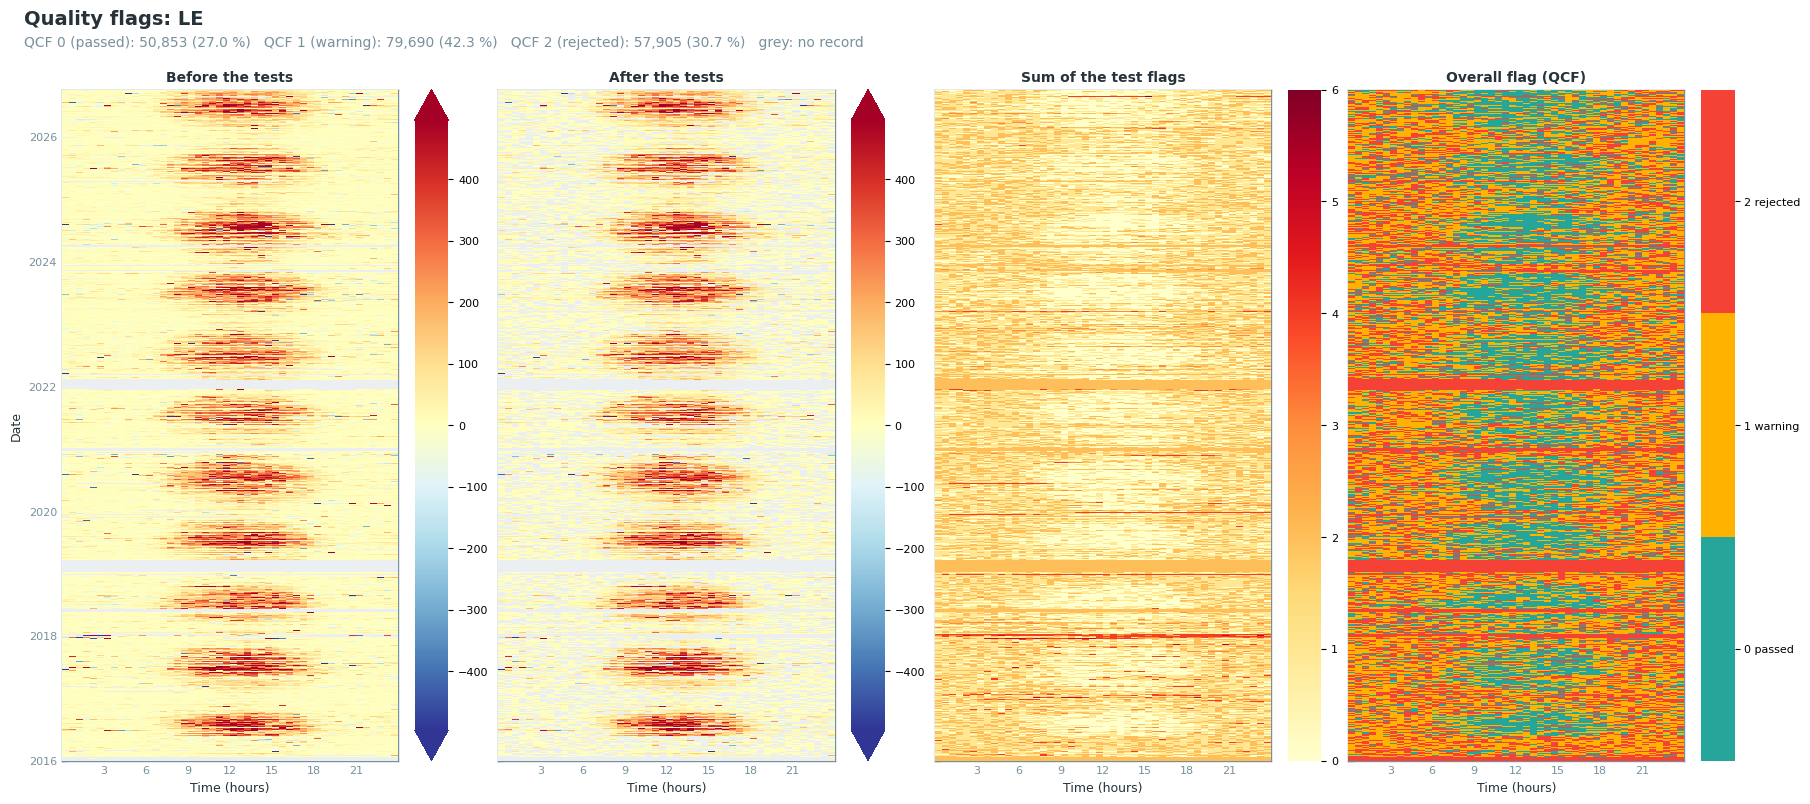

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: LE
Measured records: 174,988 of 188,448
Missing records: 13,460 (7.14 %), flagged by the missing-values test
                                                  Pass     Warn     Fail    Fail      Not
Test                        Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────
L2_LE_SSITC                 all      174,988    52,194   80,020   42,774   24.44        0
                            day       88,841    38,869   35,939   14,033   15.80        0
                            night     86,147    13,325   44,081   28,741   33.36        0
                                                                                         
L2_LE_SCF                   all      174,988   169,971    4,613      404    0.23        0
                            day       88,841    86,446    2,170      225    0.25        0
                            night     86,147    83,525    2,443      179    0.21        0
                                                                                         
L2_LE_SIGNAL_STRENGTH       all      174,988   173,685        0    1,303    0.74        0
                            day       88,841    88,297        0      544    0.61        0
                            night     86,147    85,388        0      759    0.88        0
                                                                                         
L2_LE_H2O_VM97_SPIKE_HF     all      174,988   173,870        0    1,118    0.64        0
                            day       88,841    88,376        0      465    0.52        0
                            night     86,147    85,494        0      653    0.76        0
                                                                                         
L2_LE_H2O_VM97_DROPOUT_HF   all      174,988   174,988        0        0    0.00        0
                            day       88,841    88,841        0        0    0.00        0
                            night     86,147    86,147        0        0    0.00        0

## Step 3: no storage term (Level 3.1)

No storage term is added: FLUXNET2015 and ONEFlux take LE as a turbulent flux without storage
correction (Pastorello et al. 2020). Level 3.1 runs with `set_storage_to_zero=True`, because the
later levels need it ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#storage-term)).

In [8]:
data = run_level31(data, set_storage_to_zero=True)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux LE_L3.1 from flux LE + storage term set to zero

After L3.1: 130,543 valid records (col: LE_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests. Check each plot, then accept the test with `sod.addflag()` in the cell below it.

1. Periods in `REMOVE_DATES`, removed by hand; the reasons are in the site documentation.
2. Absolute limits `ABSLIM`.
3. Hampel filter on double differences: single spikes.
4. Hampel filter per time of day: values wrong for their time of day.

Negative values at night are not tested: LE can be negative at night (dew). How the tests work: [diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#outlier-tests). The table at the end of this step lists
further tests.

In [9]:
data, sod = make_level32_detector(data)

### 📊 Plot: periods removed by hand

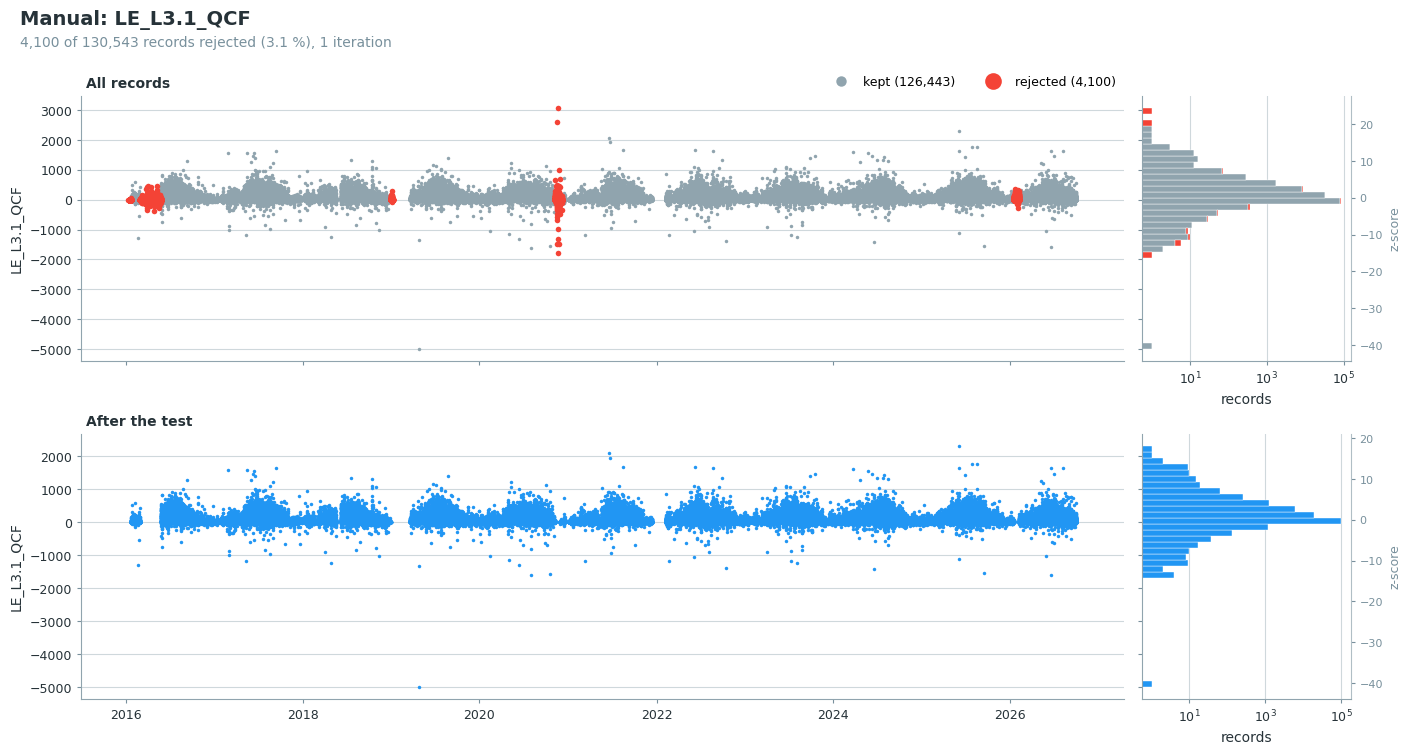

In [10]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

In [11]:
if _remove:
    sod.addflag()  # accept the manual removal

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_MANUAL_TEST to flag data

### 📊 Plot: absolute limits

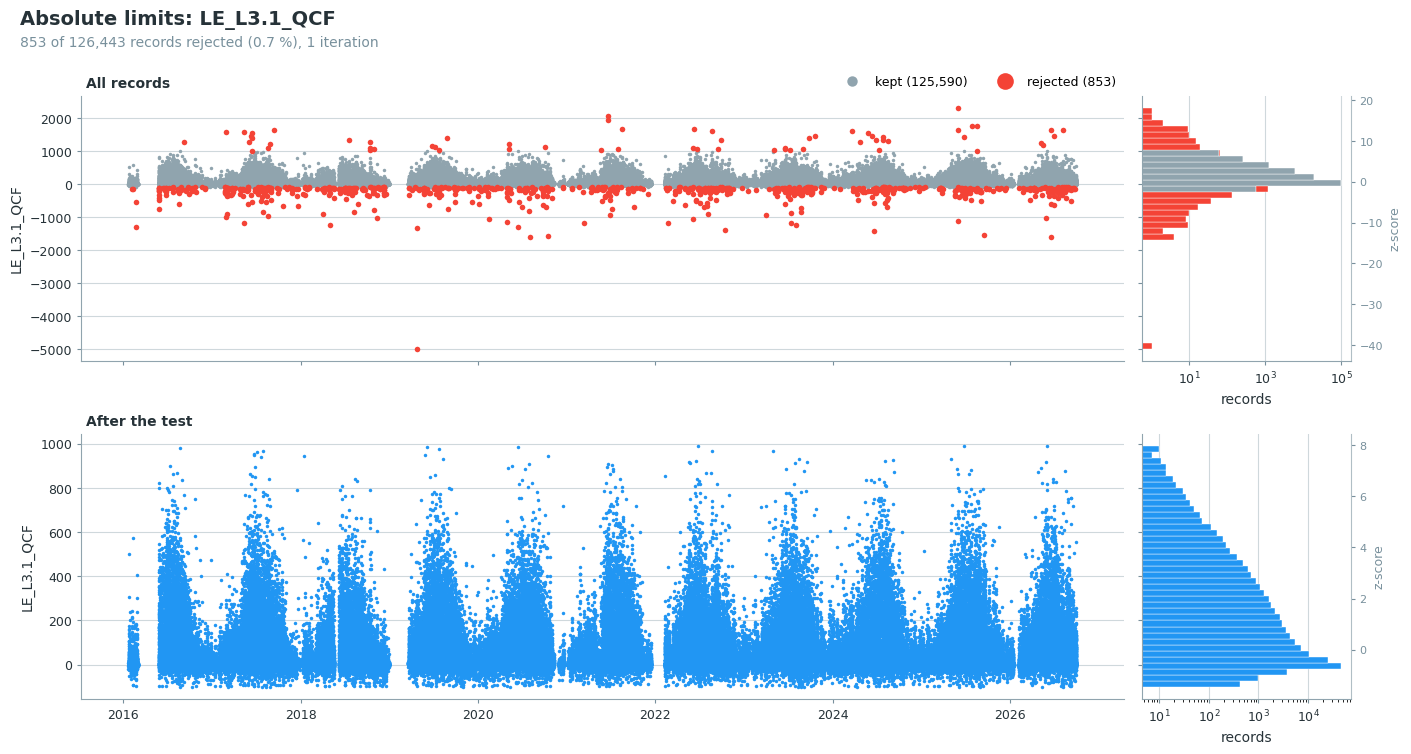

In [12]:
sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=True, verbose=True)

In [13]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_ABSLIM_TEST to flag data

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:  2783 (  2.22%) | Day:  1032 | Night:  1751

[Dt/Nt] ITER #02 | Outliers:   424 (  0.35%) | Day:   134 | Night:   290

[Dt/Nt] ITER #03 | Outliers:   102 (  0.08%) | Day:    36 | Night:    66

[Dt/Nt] ITER #04 | Outliers:    21 (  0.02%) | Day:     6 | Night:    15

[Dt/Nt] ITER #05 | Outliers:     4 (  0.00%) | Day:     0 | Night:     4

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

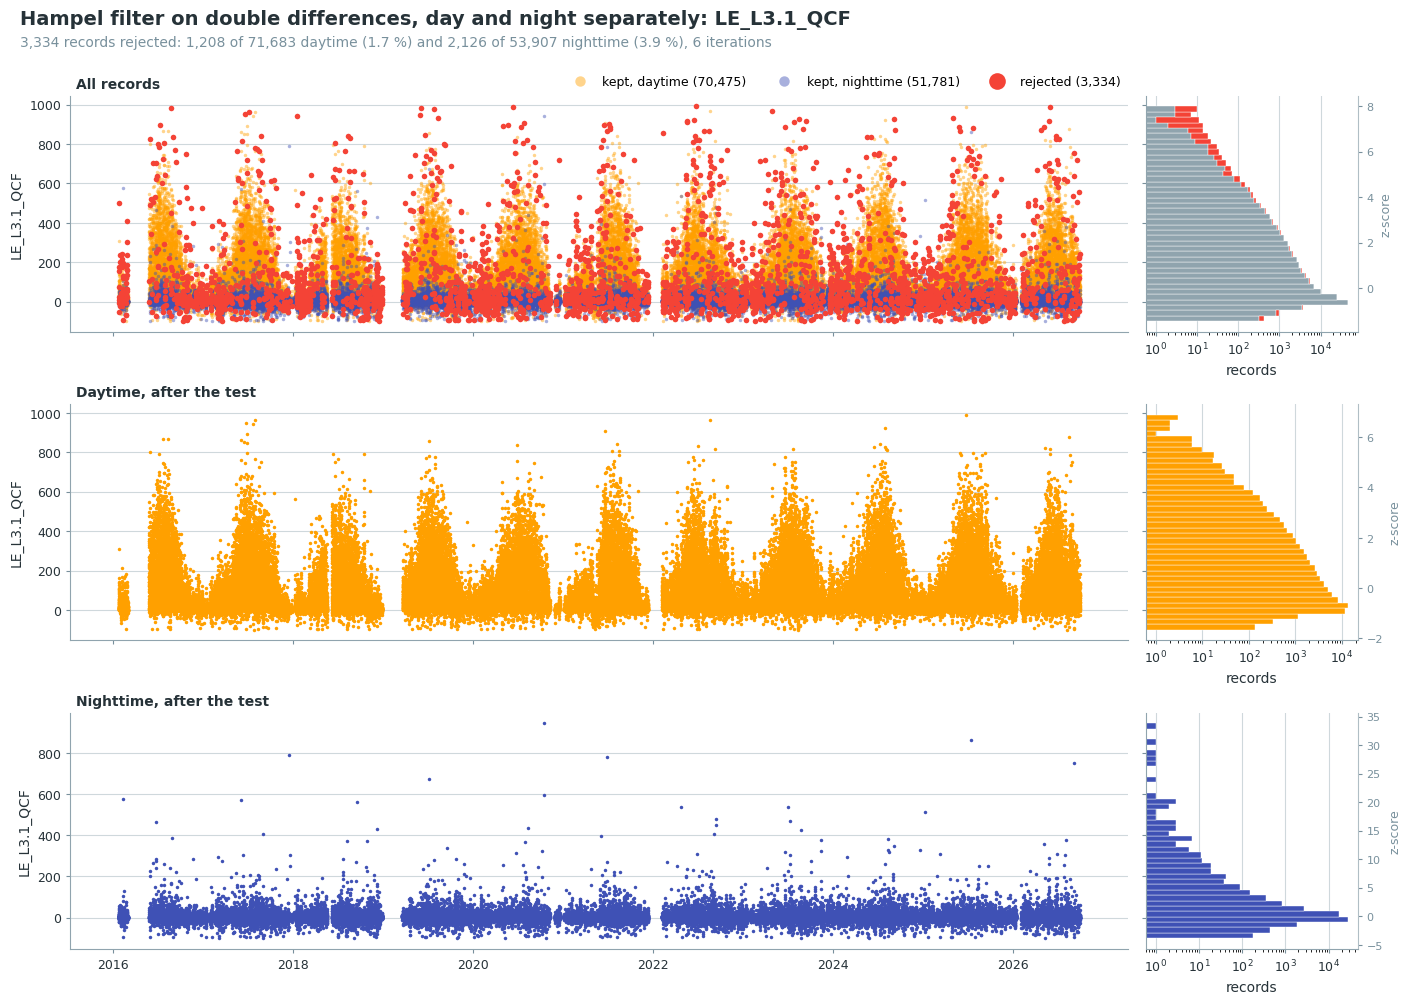

In [14]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:  2392 (  1.96%) | Day:   726 | Night:  1666

[Dt/Nt] ITER #02 | Outliers:   303 (  0.25%) | Day:    82 | Night:   221

[Dt/Nt] ITER #03 | Outliers:    59 (  0.05%) | Day:    15 | Night:    44

[Dt/Nt] ITER #04 | Outliers:     6 (  0.01%) | Day:     2 | Night:     4

[Dt/Nt] ITER #05 | Outliers:     1 (  0.00%) | Day:     0 | Night:     1

[Dt/Nt] ITER #06 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

! Hampel: 256 record(s) were not tested because their time-of-day window held fewer than 
min_records=10 values. They keep flag 0. Consider a longer window_length or more time_of_day_slots.

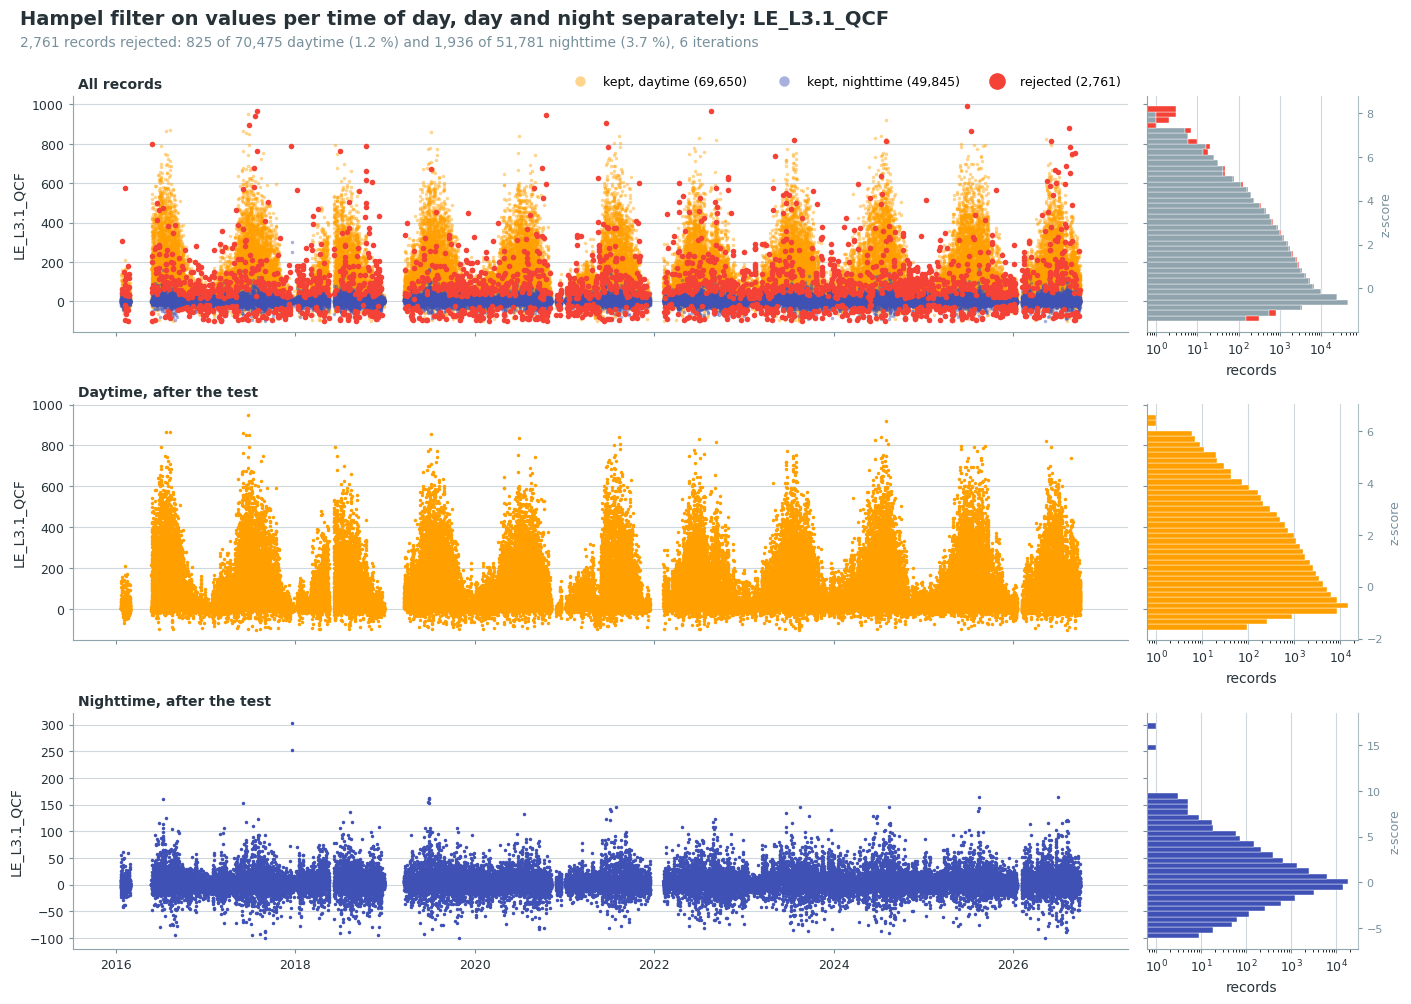

In [16]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [17]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [18]:
_used = {'flag_manualremoval_test', 'flag_outliers_abslim_test', 'flag_outliers_hampel_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,yes
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [19]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 119,495 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

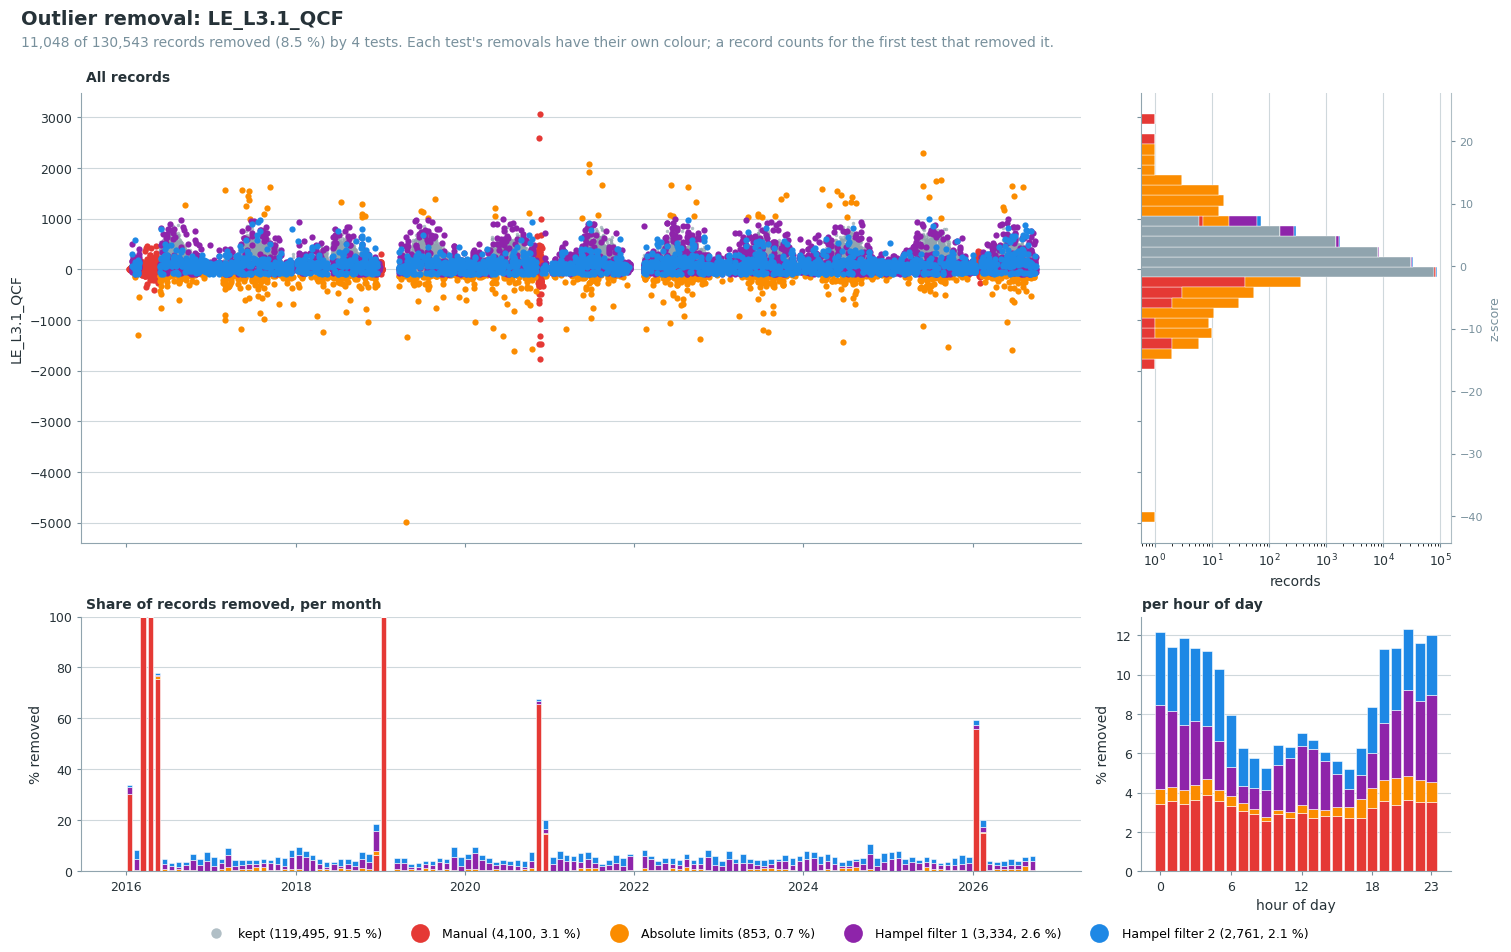

In [20]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

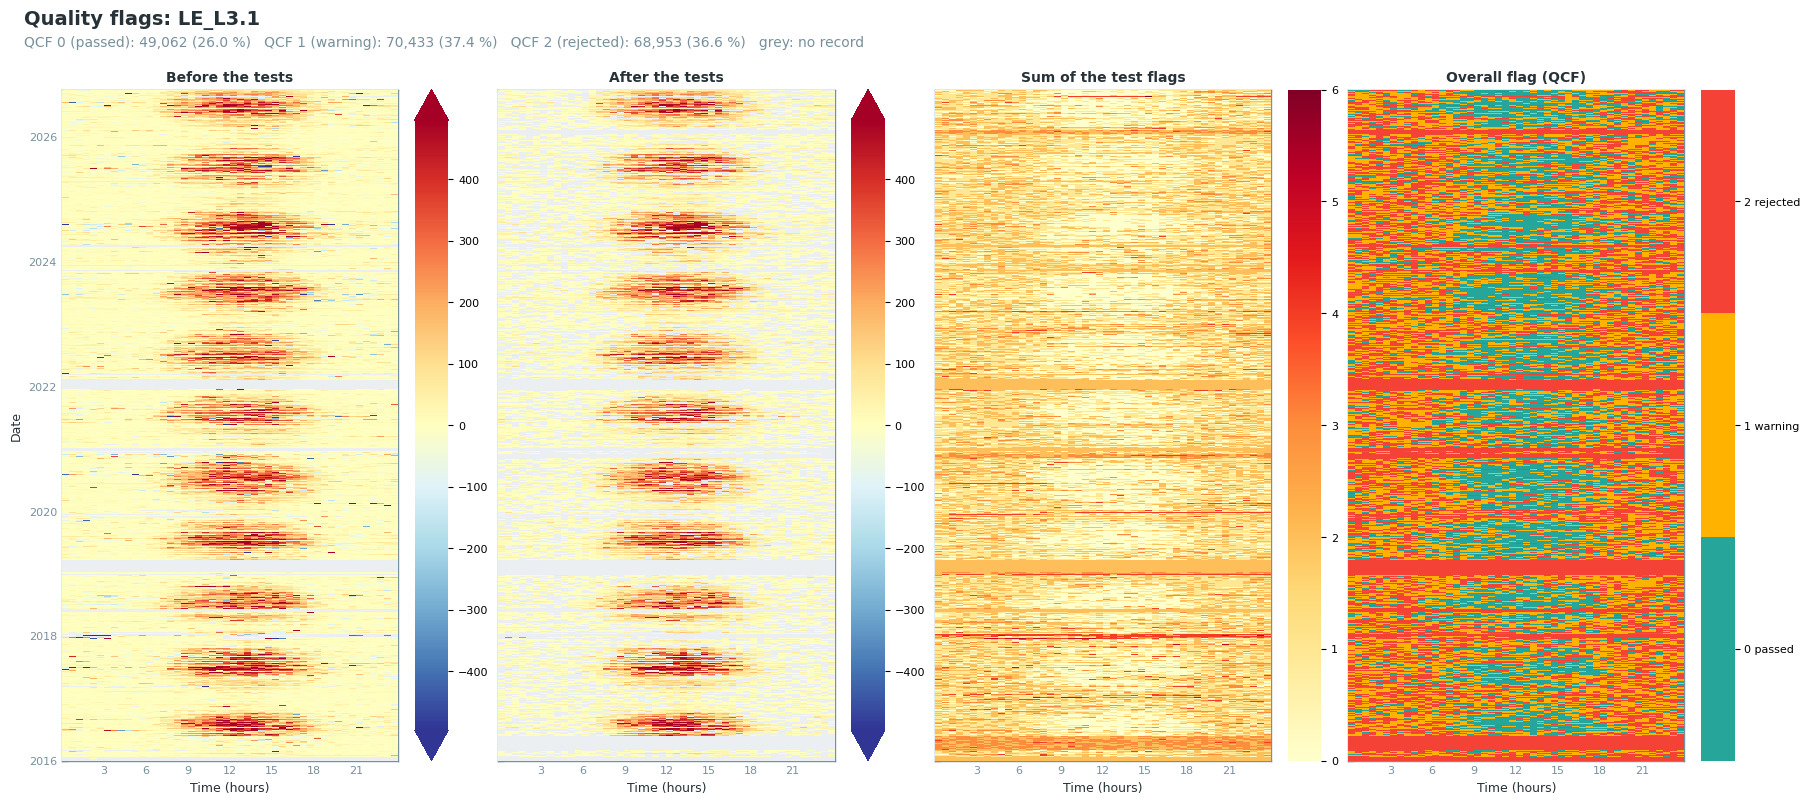

In [21]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [22]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: LE_L3.1
Measured records: 174,988 of 188,448
Missing records: 13,460 (7.14 %), flagged by the missing-values test
                                                          Pass     Warn     Fail    Fail      Not
Test                                Period    Tested       (0)      (1)      (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────────────────
L2_LE_SSITC                         all      174,988    52,194   80,020   42,774   24.44        0
                                    day       88,841    38,869   35,939   14,033   15.80        0
                                    night     86,147    13,325   44,081   28,741   33.36        0
                                                                                                 
L2_LE_SCF                           all      174,988   169,971    4,613      404    0.23        0
                                    day       88,841    86,446    2,170      225    0.25        0
                                    night     86,147    83,525    2,443      179    0.21        0
                                                                                                 
L2_LE_SIGNAL_STRENGTH               all      174,988   173,685        0    1,303    0.74        0
                                    day       88,841    88,297        0      544    0.61        0
                                    night     86,147    85,388        0      759    0.88        0
                                                                                                 
L2_LE_H2O_VM97_SPIKE_HF             all      174,988   173,870        0    1,118    0.64        0
                                    day       88,841    88,376        0      465    0.52        0
                                    night     86,147    85,494        0      653    0.76        0
                                                                                                 
L2_LE_H2O_VM97_DROPOUT_HF           all      174,988   174,988        0        0    0.00        0
                                    day       88,841    88,841        0        0    0.00        0
                                    night     86,147    86,147        0        0    0.00        0
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_MANUAL     all      130,543   126,443        0    4,100    3.14   44,445
                                    day       74,040    72,056        0    1,984    2.68   14,801
                                    night     56,503    54,387        0    2,116    3.74   29,644
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_ABSLIM     all      126,443   125,590        0      853    0.67   48,545
                                    day       72,056    71,683        0      373    0.52   16,785
                                    night     54,387    53,907        0      480    0.88   31,760
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL     all      125,590   122,256        0    3,334    2.65   49,398
                                    day       71,683    70,475        0    1,208    1.69   17,158
                                    night     53,907    51,781        0    2,126    3.94   32,240
                                                                                                 
L3.2_LE_L3.1_QCF_OUTLIER_HAMPEL_2   all      122,256   119,495        0    2,761    2.26   52,732
                                    day       70,475    69,650        0      825    1.17   18,366
                                    night     51,781    49,845        0    1,936    3.74   34,366

## Step 5: no USTAR filter (Level 3.3)

No USTAR filter for LE, as in FLUXNET2015 and ONEFlux (Pastorello et al. 2020). The gap-filling
needs Level 3.3, so it runs one scenario, `CUT_NONE`, with a threshold of 0, which removes no record
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#ustar-filter)).

In [23]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_NONE

### Records for gap-filling and highest-quality records

The records the gap-filling starts from (QCF 0 and 1, columns `_QCF`) and the highest-quality
records (QCF 0, columns `_QCF0`) for analyses without gap-filled values
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#gapfilling-input)).

### 📋 Table: records for gap-filling

In [24]:
report_gapfilling_input(data);

Records for gap-filling
                      removed:   removed:              used:    used:    used:    used:
USTAR      measured      tests      USTAR      used    QCF 0    QCF 1      day    night
───────────────────────────────────────────────────────────────────────────────────────
CUT_NONE    174,988     55,493          0   119,495   49,062   70,433   69,650   49,845
                93%        29%         0%       63%      26%      37%      37%      26%
Records, and their share of all 188,448 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

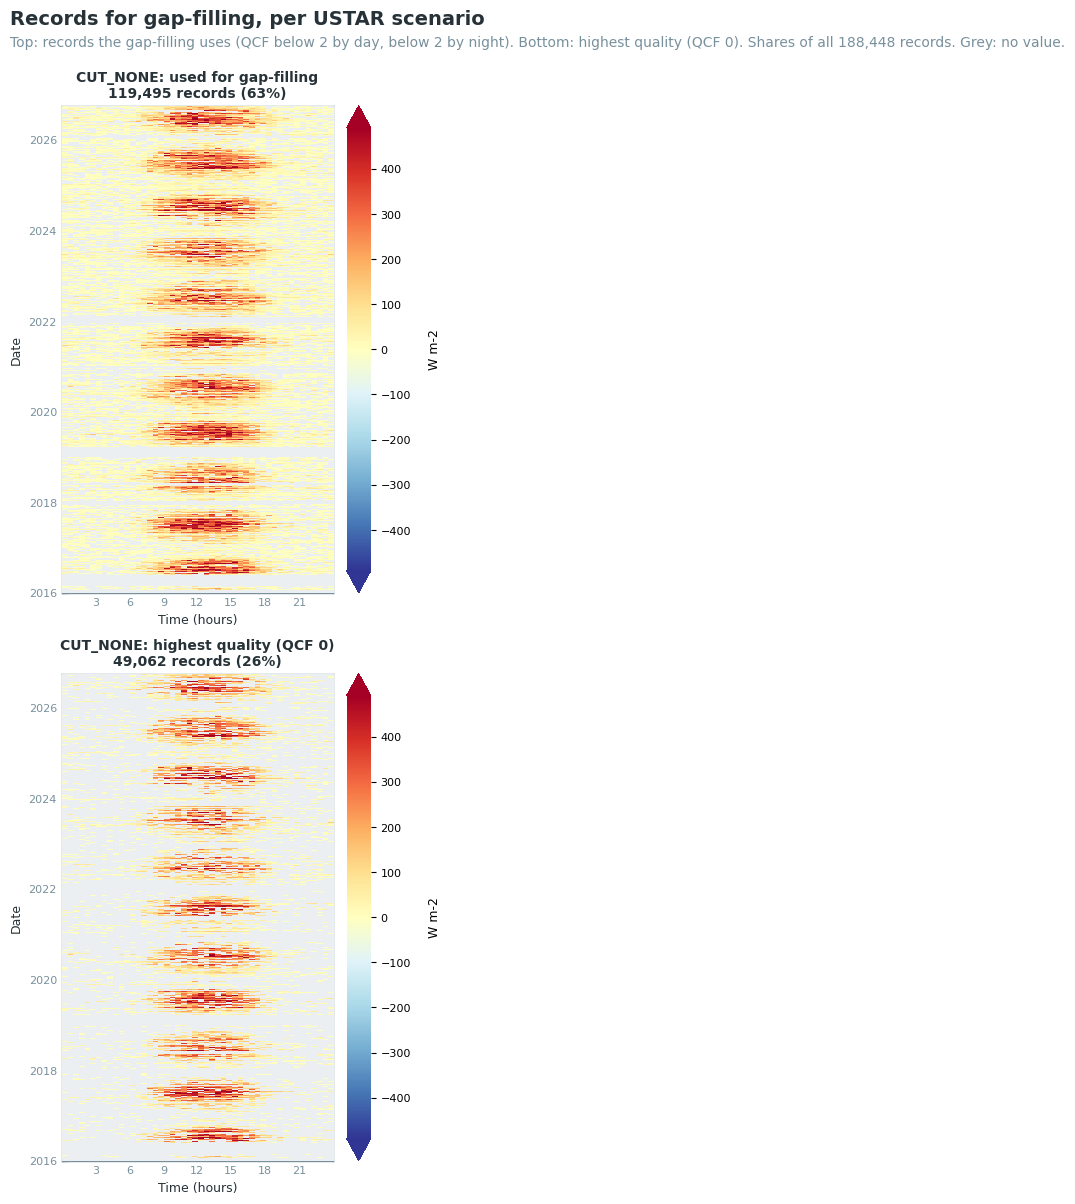

In [25]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [26]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR      missing %    gaps   long gaps   longest gap (days)   worst month   worst month missing %
───────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE        36.6   27555          30                 86.0           Jan                    57.8
A long gap lasts at least 1 day.

## Step 6: model features

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [27]:
engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

## Step 7: gap-filling (Level 4.1)

XGBoost fills the gaps of this dataset, MDS for comparison (Step 10).

### XGBoost

One model per year, trained on three years, with features selected by SHAP
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#xgboost-gapfilling)).

The number of trees is chosen once for all models by blocked cross-validation
([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [28]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    n_estimators_cv=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) in `mode='diive'`, filling every gap from
measured driver values only ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#mds-gapfilling)).

**Skipped** when `RUN_MDS = False`.

In [29]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: results

How many records were measured and how many were filled, then the annual sum of LE in MJ m-2, for
each gap-filling method. The share measured is given in brackets: a year with long gaps rests
largely on the model. An incomplete year is marked.

### 📋 Table: measured and filled records

In [30]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR      records   measured   filled   filled %
───────────────────────────────────────────────────────────
MDS       CUT_NONE   188,448    119,495   68,953       36.6
XGBoost   CUT_NONE   188,448    119,495   68,953       36.6
MDS (CUT_NONE): LE_L3.1_L3.3_CUT_NONE_QCF -> LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS
XGBoost (CUT_NONE): LE_L3.1_L3.3_CUT_NONE_QCF -> LE_L3.1_L3.3_CUT_NONE_QCF_gfXG

### 📋 Table: annual sums of LE

In [31]:
report_annual_sums(data, gain=W_TO_MJ, units='MJ m-2');

Annual sums (MJ m-2)
                 MDS       XGBoost
year        CUT_NONE      CUT_NONE
──────────────────────────────────
2016     1,588 (49%)   1,502 (49%)
2017     1,517 (64%)   1,517 (64%)
2018     1,414 (63%)   1,406 (63%)
2019     1,435 (55%)   1,464 (55%)
2020     1,467 (62%)   1,482 (62%)
2021     1,338 (66%)   1,349 (66%)
2022     1,520 (63%)   1,532 (63%)
2023     1,579 (70%)   1,581 (70%)
2024     1,545 (68%)   1,550 (68%)
2025     1,598 (71%)   1,610 (71%)
2026 *   1,391 (68%)   1,416 (68%)
In brackets: the share of the year's records that were measured.
* Incomplete year (2026): the sum covers only part of it.

## Step 9: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. The number of trees is chosen without the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [32]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
XGBoost   CUT_NONE   2016   0.816   46.95   26.81   12.75   485.7
XGBoost   CUT_NONE   2017   0.816   46.95   26.81   12.75   485.7
XGBoost   CUT_NONE   2018   0.807   47.96   27.79   13.45   423.0
XGBoost   CUT_NONE   2019   0.792   48.64   27.71   13.48   520.4
XGBoost   CUT_NONE   2020   0.795   49.44   27.40   12.81   608.7
XGBoost   CUT_NONE   2021   0.780   49.63   27.34   12.73   619.3
XGBoost   CUT_NONE   2022   0.782   48.99   27.51   12.83   607.9
XGBoost   CUT_NONE   2023   0.794   48.58   27.82   12.90   462.0
XGBoost   CUT_NONE   2024   0.811   47.87   26.68   11.48   450.6
XGBoost   CUT_NONE   2025   0.805   50.79   28.54   12.66   556.2
XGBoost   CUT_NONE   2026   0.805   50.79   28.54   12.66   556.2
XGBoost   CUT_NONE   mean   0.800   48.78   27.54   12.77   525.1
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_NONE).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [33]:
report_model_overview(data);

Gap-filling models
                  trained                                          final    test    test            fall-
USTAR      year   on          features    train    test   trees      fit      R²    RMSE   filled    back
─────────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   2016   2016-2018         75   23,205   7,752     100   30,957   0.816   46.95    8,981       0
CUT_NONE   2017   2016-2018         75   23,205   7,752     100   30,957   0.816   46.95    6,248       0
CUT_NONE   2018   2017-2019         75   24,098   7,961     100   32,059   0.807   47.96    6,422       0
CUT_NONE   2019   2018-2020         75   23,880   7,738     100   31,618   0.792   48.64    7,831       0
CUT_NONE   2020   2019-2021         75   24,094   7,915     100   32,009   0.795   49.44    6,737       0
CUT_NONE   2021   2020-2022         75   25,002   8,334     100   33,336   0.780   49.63    6,031       0
CUT_NONE   2022   2021-2023         75   25,954   8,768     100   34,722   0.782   48.99    6,504       0
CUT_NONE   2023   2022-2024         75   26,309   8,860     100   35,169   0.794   48.58    5,303       0
CUT_NONE   2024   2023-2025         75   27,349   9,197     100   36,546   0.811   47.87    5,632       0
CUT_NONE   2025   2024-2026         75   24,791   8,505     100   33,296   0.805   50.79    5,127       0
CUT_NONE   2026   2024-2026         75   24,791   8,505     100   33,296   0.805   50.79    4,137       0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, which
the model did not see.
trees: 100 for every model, chosen by blocked cross-validation (report_tree_selection).
final fit: the gaps are filled by a model refitted on all complete records with that number of trees. 
filled / fallback: gaps of the model year filled by this model, or by the fallback model on timestamp 
features where a driver was missing.
XGBoost: learning_rate=0.05, max_depth=6, n_estimators=100, n_jobs=-1, random_state=42

### 📋 Table: number of trees from blocked cross-validation

The scores on held-out blocks of days at the chosen number of trees, next to the scores on the
random test records. The blocked scores describe gaps of days, the random ones single missing
records ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#tree-selection)).

In [34]:
report_tree_selection(data);

Number of trees from blocked cross-validation
                      blocked   blocked   blocked   random   random
pool        records      RMSE       MAE        R²     RMSE       R²
───────────────────────────────────────────────────────────────────
2016-2018    23,205     52.21     29.60     0.776    46.95    0.816
2017-2019    24,098     52.34     29.84     0.767    47.96    0.807
2018-2020    23,880     50.33     29.17     0.774    48.64    0.792
2019-2021    24,094     52.64     29.43     0.771    49.44    0.795
2020-2022    25,002     52.85     29.63     0.757    49.63    0.780
2021-2023    25,954     53.84     29.90     0.747    48.99    0.782
2022-2024    26,309     52.46     29.69     0.769    48.58    0.794
2023-2025    27,349     51.82     28.37     0.786    47.87    0.811
2024-2026    24,791     53.11     29.89     0.780    50.79    0.805
100 trees for every model: the minimum of the median error curve of the pools, rounded to ten (up to
1000 tested). USTAR scenario CUT_NONE.
blocked: 5-fold cross-validation on the training records of each pool, holding out whole 14-day 
blocks, at the chosen number of trees. R² from the RMSE and the variance of the target.
random: the test records of the models of that pool, random single half-hours that the models did 
not see. The difference shows how much harder gaps of days are than single missing records.

### 📊 Plot: number of trees from blocked cross-validation

The error on held-out blocks against the number of trees, one line per pool, and the chosen
number. The curves should flatten well before the largest number tested.

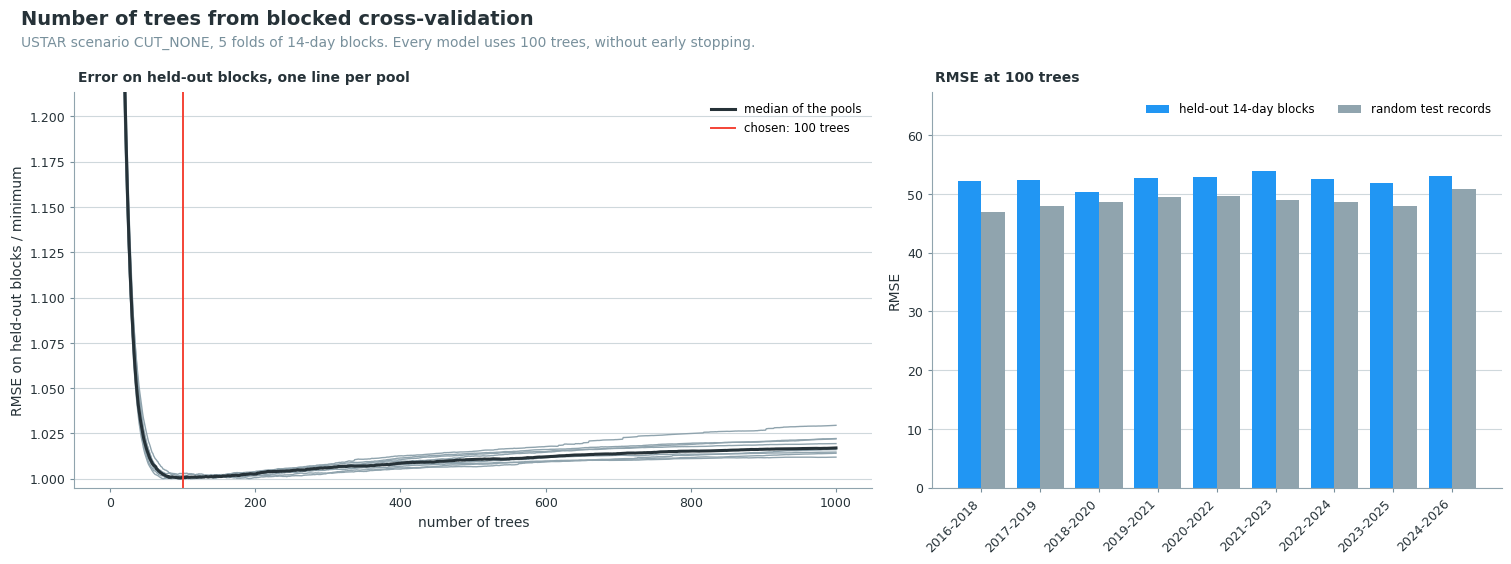

In [35]:
plot_tree_selection(data);

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [36]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR      year      R²    RMSE     MAE   MedAE    MaxE
─────────────────────────────────────────────────────────────────
MDS       CUT_NONE   all    0.742   55.99   31.48   13.77   848.9
XGBoost   CUT_NONE   2016   0.868   40.04   23.99   12.02   367.3
XGBoost   CUT_NONE   2017   0.868   40.04   23.99   12.02   367.3
XGBoost   CUT_NONE   2018   0.858   40.96   24.75   12.72   418.7
XGBoost   CUT_NONE   2019   0.854   40.44   24.44   12.84   456.8
XGBoost   CUT_NONE   2020   0.859   41.26   24.27   12.17   453.4
XGBoost   CUT_NONE   2021   0.846   41.96   24.60   12.19   482.7
XGBoost   CUT_NONE   2022   0.846   41.86   24.44   11.90   470.5
XGBoost   CUT_NONE   2023   0.854   41.52   24.67   12.09   394.3
XGBoost   CUT_NONE   2024   0.866   40.83   23.75   11.18   380.5
XGBoost   CUT_NONE   2025   0.864   41.97   24.84   12.03   391.4
XGBoost   CUT_NONE   2026   0.864   41.97   24.84   12.03   391.4
XGBoost   CUT_NONE   mean   0.859   41.17   24.42   12.11   415.8
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [37]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2016         2016-2018              
2017         2016-2018              
2018         2017-2019              
2019         2018-2020              
2020         2019-2021              
2021         2020-2022              
2022         2021-2023              
2023         2022-2024              
2024         2023-2025              
2025         2024-2026              
2026         2024-2026              
Not available for MDS (CUT_NONE) (does not pool years).

### 📋 Table: most important features (SHAP)

In [38]:
report_gapfilling_feature_importances(data, ustar_scenario=USTAR_SCENARIO)

Feature importances, XGBoost (CUT_NONE): top 10 of 75 features, mean |SHAP|
 #   feature                                   2016    2017    2018    2019    2020    2021    2022    2023    2024    2025    2026    mean
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 1   .SW_IN_T1_47_1_gfXG_ROLLMAX2             32.79   32.79   27.51   21.03   26.48   27.45   27.86   26.37   28.25   30.68   30.68   28.35
 2   SW_IN_T1_47_1_gfXG                       23.43   23.43   26.27   23.96   22.64   23.23   24.61   29.11   24.97   24.19   24.19   24.55
 3   .SW_IN_T1_47_1_gfXG_MEAN2                 3.02    3.02    6.82   12.58   11.07    9.85    7.67    9.62    7.48    6.77    6.77    7.70
 4   .DOY_COS                                  5.72    5.72    6.49    8.42    2.53    1.57    1.41    2.90    4.79    8.63    8.63    5.17
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX4              3.73    3.73    3.33    2.01    4.36    4.22    3.06    2.42    3.81    6.89    6.89    4.04
 6   .TA_T1_47_1_HOMOGENIZED_gfXG_ROLLMIN48    4.84    4.84    2.90    2.42    3.27    6.78    5.07    2.62    2.16    2.05    2.05    3.55
 7   .VPD_T1_47_1_HOMOGENIZED_SD2              2.25    2.25    2.63    3.14    2.95    3.15    2.35    3.77    2.91    3.35    3.35    2.92
 8   .DOY_SIN                                  3.05    3.05    2.68    1.74    3.15    3.83    3.97    1.15    1.86    2.82    2.82    2.74
 9   .TA_T1_47_1_HOMOGENIZED_gfXG_ROLLMIN24    0.91    0.91    1.04    0.86    2.65    5.15    5.47    2.68    3.14    0.98    0.98    2.25
10   .SW_IN_T1_47_1_gfXG_MEAN4                 3.15    3.15    0.90    0.23    1.11    2.00    2.59    2.00    1.62    3.00    3.00    2.07

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_NONE) (no model trained).

### 📊 Plot: feature ranks per year

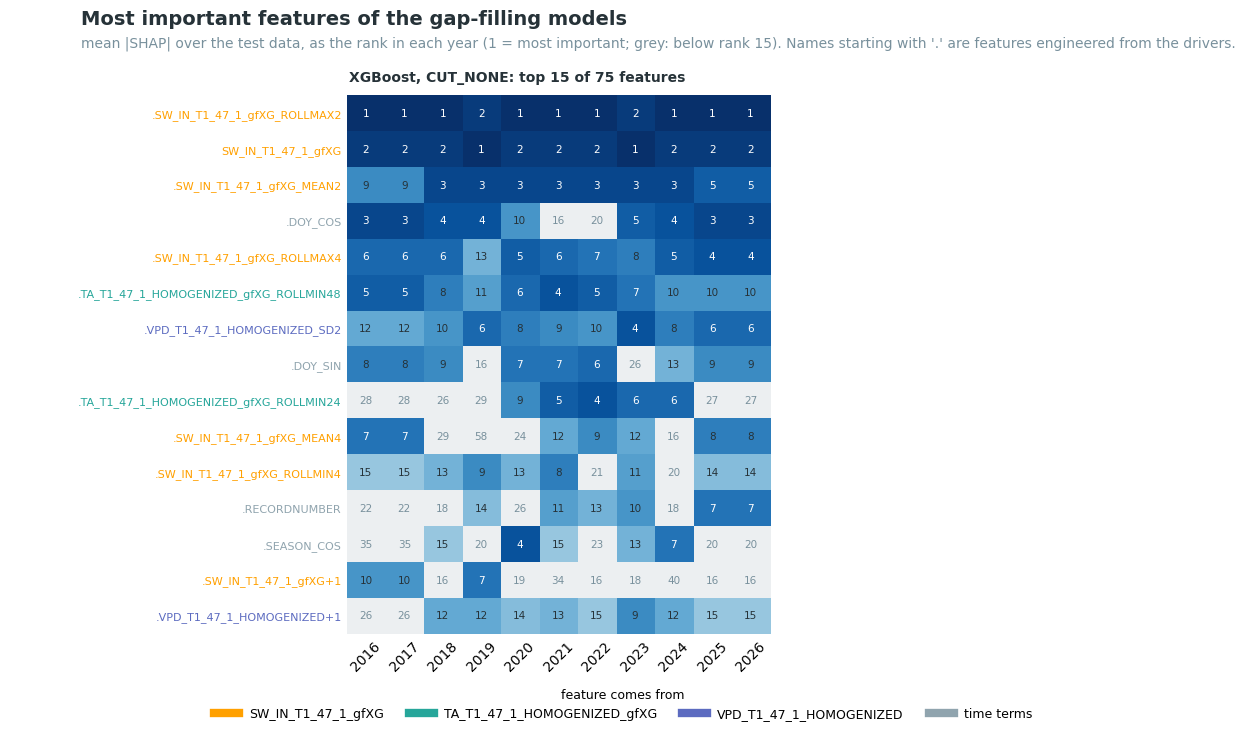

In [39]:
plot_feature_ranks_per_year(data)

## Step 10: result plots

### 📊 Plot: LE by quality class, heatmaps, XGBoost

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

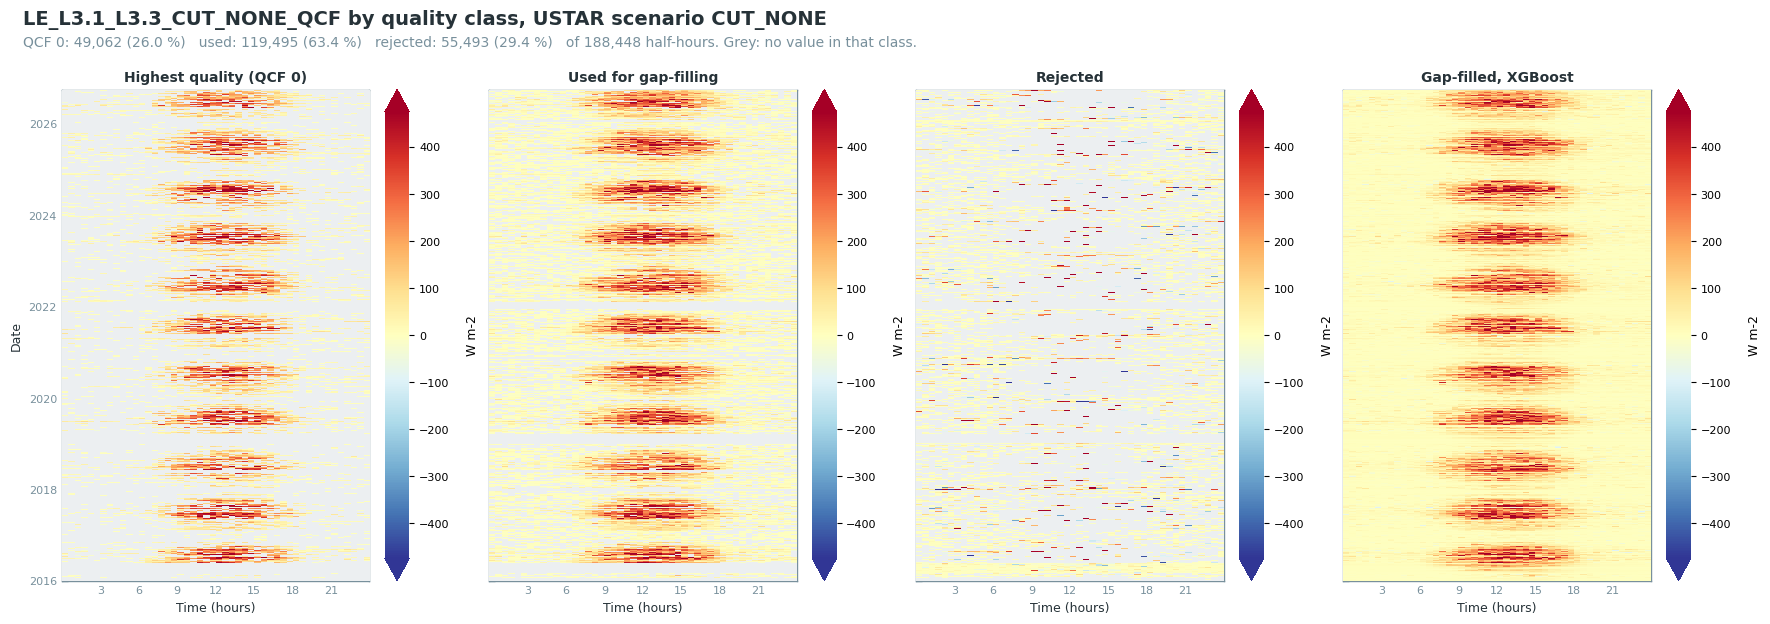

In [40]:
plot_quality_heatmaps(data, ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: LE by quality class, day and night, XGBoost

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

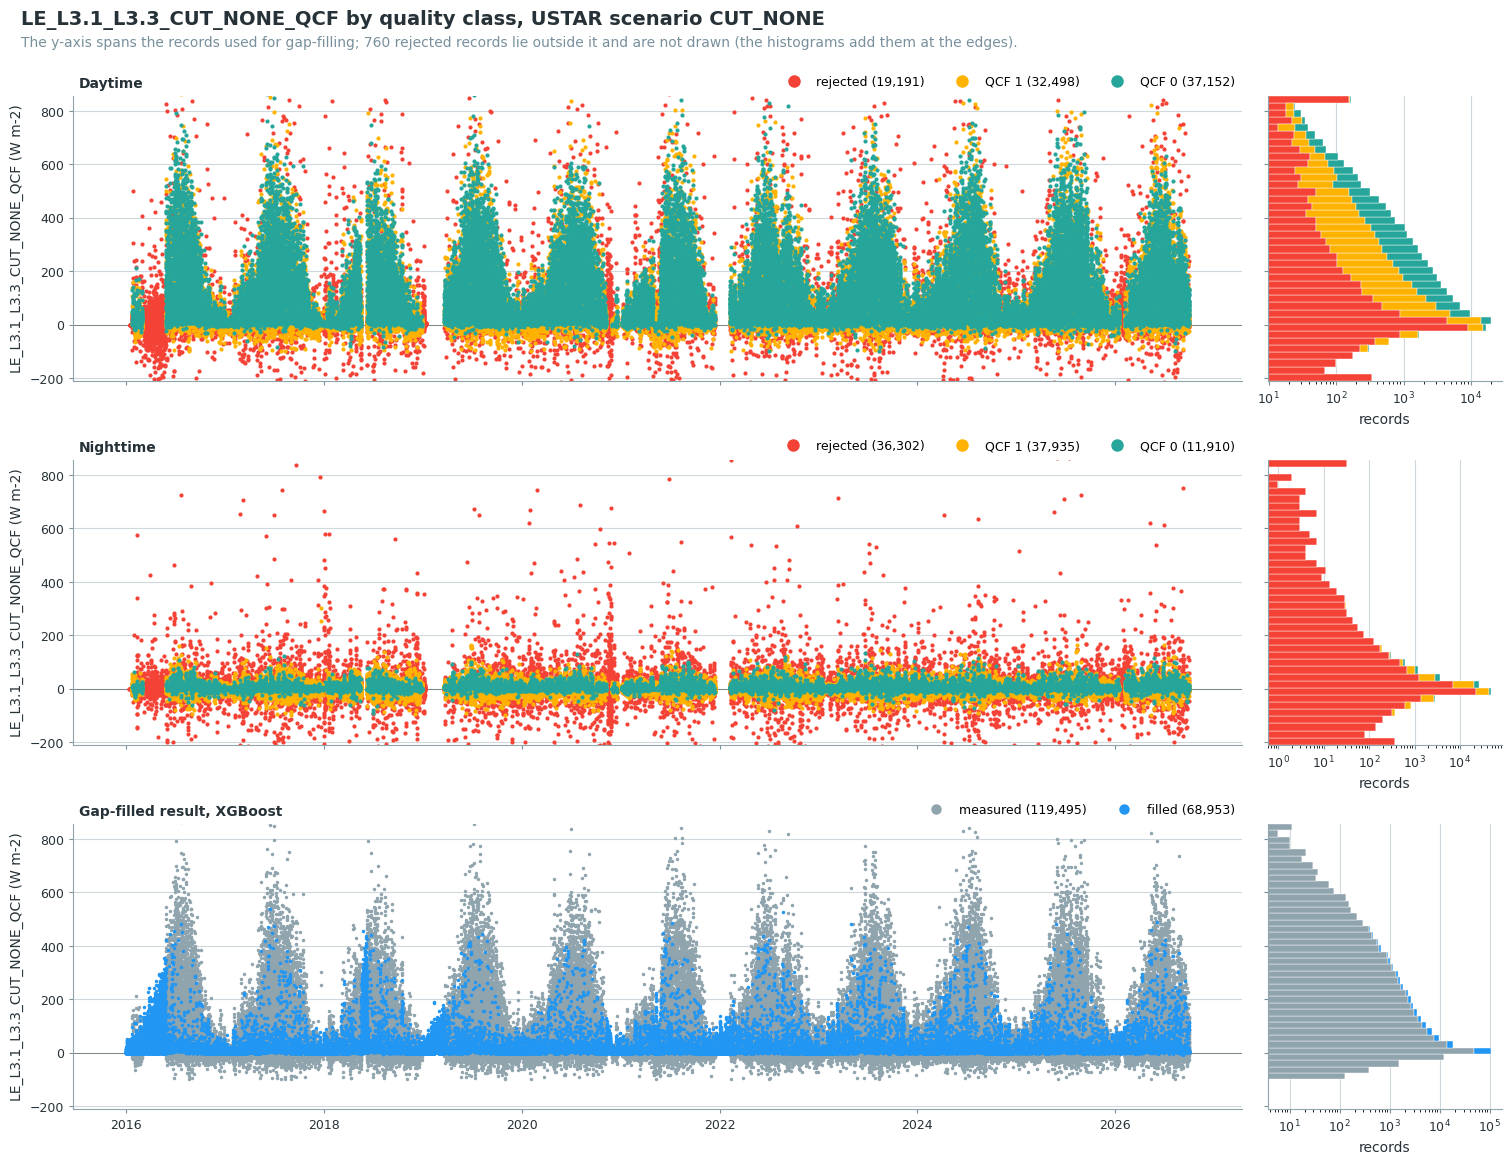

In [41]:
plot_quality_timeseries(data, ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled LE

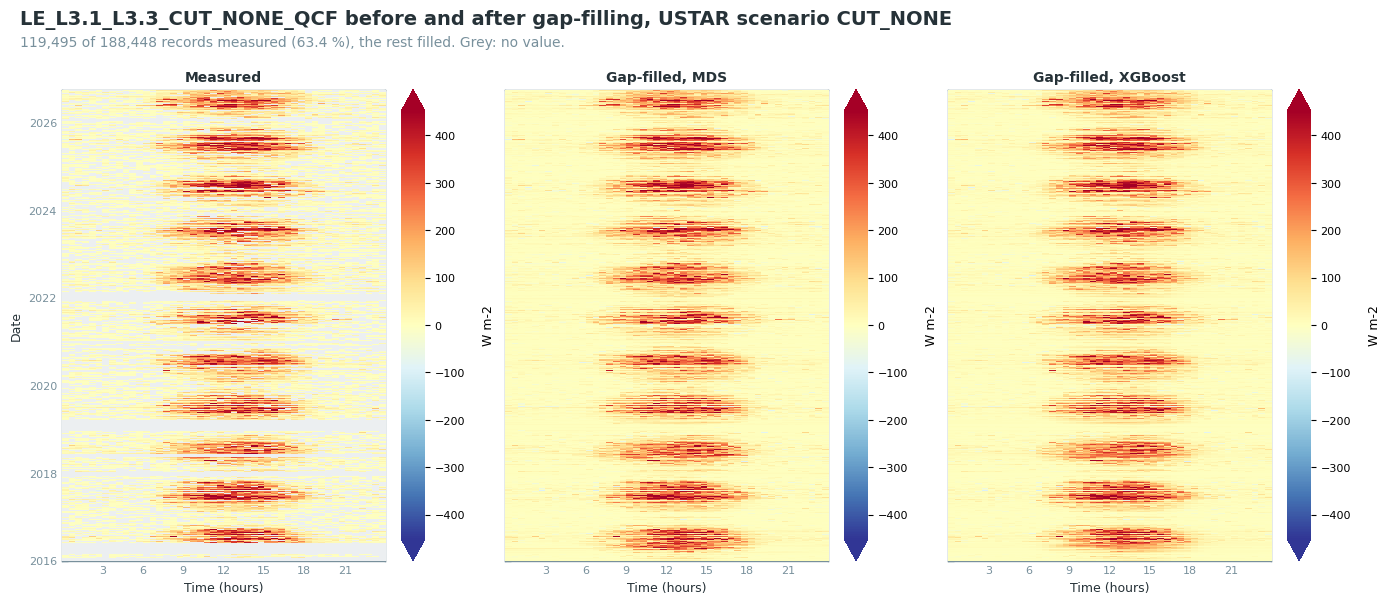

In [42]:
data.plot_gapfilled_heatmaps(ustar_scenario=USTAR_SCENARIO, units=FLUX_UNITS)

### 📊 Plot: cumulative LE

One line per gap-filling method, and the measured records alone (gaps counted as zero).

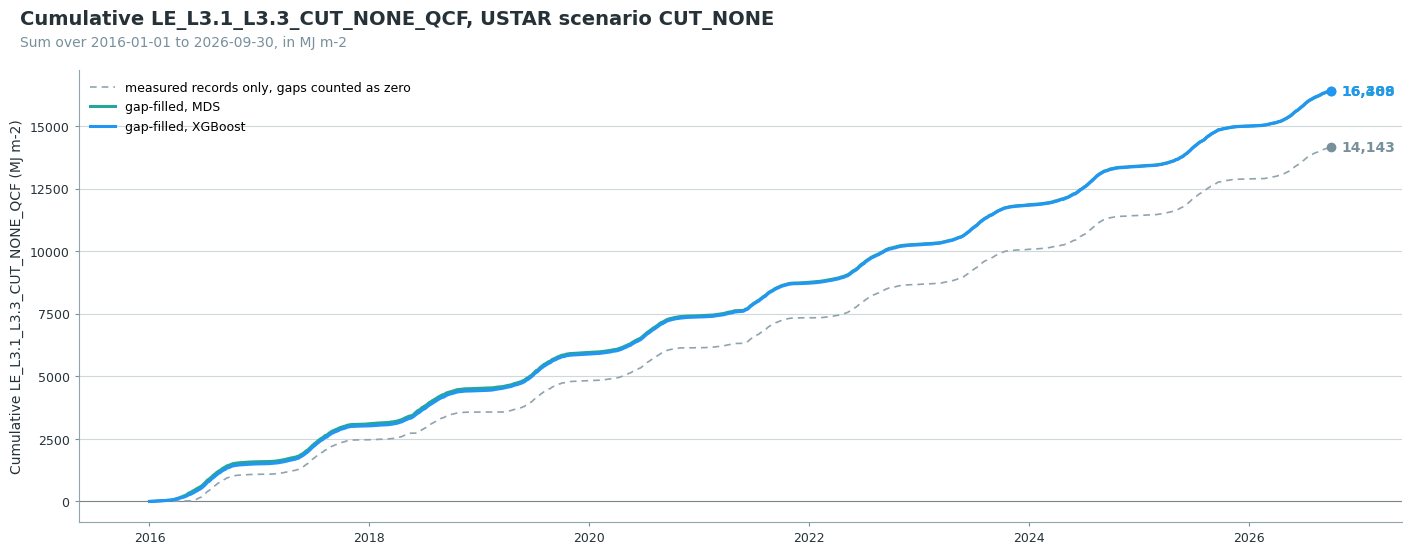

In [43]:
data.plot_cumulative_comparison(
    ustar_scenario=USTAR_SCENARIO,
    conv_factor=W_TO_MJ,
    units='MJ m-2',
)

### 📊 Plot: cumulative LE per year

One panel per gap-filling method, on the same y-axis. One line per year; the band is the mean ± 1 SD
of the full years. An incomplete last year is left out of the band.

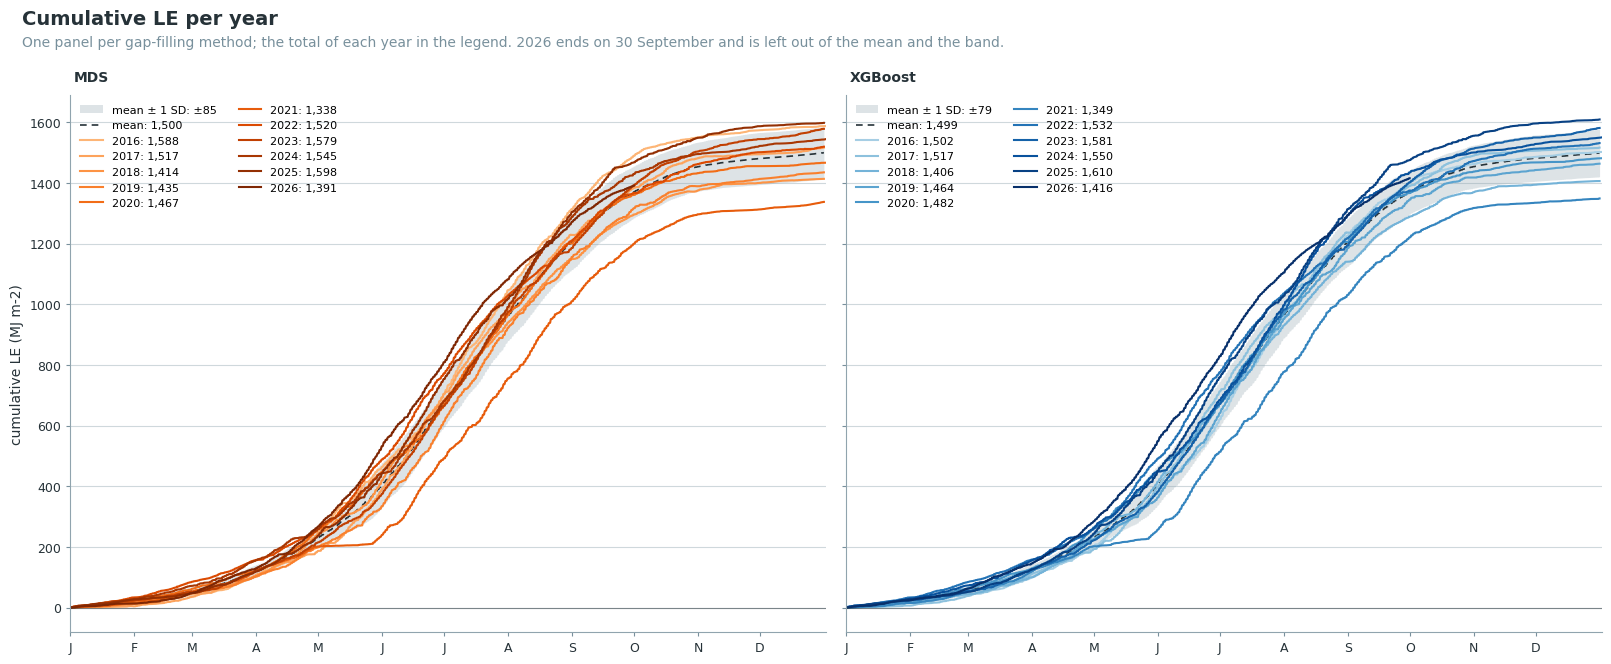

In [44]:
# One panel per gap-filling method, on a shared y-axis. Years run from light to dark, so the most
# recent year is the darkest line.
_gf = data.gapfilled_cols()
_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
_months = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
# A last year that ends before 31 December stays out of the mean and the band.
_end = data.fpc_df.index[-1]
_partial = [_end.year] if (_end.month, _end.day) != (12, 31) else None
fig, axes = plt.subplots(1, len(_gf), figsize=(8 * len(_gf), 6.6), sharex=True, sharey=True,
                         layout='constrained', squeeze=False)
for _ax, (_method, _cols) in zip(axes[0], _gf.items()):
    _cum = doy_cumulatives_per_year(data.fpc_df[_cols[USTAR_SCENARIO]] * W_TO_MJ)
    _cum = _cum.loc[:, _cum.notna().any()]
    _years = list(_cum.columns)
    _shades = plt.get_cmap(cp.METHOD_CMAPS.get(_method, 'Greys'))(
        np.linspace(0.35, 1.0, len(_years)) if len(_years) > 1 else [0.85])
    if len(_years) > 1:
        _ref = doy_mean_cumulative(cumulatives_per_year_df=_cum,
                                   excl_years_from_reference=_partial)
        # Day 366 exists only in leap years, so the band stops before it.
        _ref = _ref.loc[_ref.index < 366]
        # The legend gives the mean and SD of the annual totals of the full years.
        _totals = [_cum[_y].dropna().iloc[-1] for _y in _years if _y not in (_partial or [])]
        _end_mean, _end_sd = np.mean(_totals), np.std(_totals, ddof=1)
        _ax.fill_between(_ref.index, _ref['MEAN-SD'], _ref['MEAN+SD'], color=cp.KEPT,
                         alpha=0.3, linewidth=0, label=f'mean ± 1 SD: ±{_end_sd:,.0f}')
        _ax.plot(_ref.index, _ref['MEAN_DOY_TIME'], color=cp.INK, linewidth=1.2,
                 linestyle=(0, (4, 3)), label=f'mean: {_end_mean:,.0f}')
    for _shade, _year in zip(_shades, _years):
        _valid = _cum[_year].dropna()
        _ax.plot(_cum.index, _cum[_year], color=_shade, linewidth=1.5,
                 label=f"{_year}: {_valid.iloc[-1]:,.0f}")
    _ax.axhline(0, color=cp.INK, linewidth=0.8, alpha=0.5)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _names.get(_method, _method))
    _ax.set_xticks(_months, ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    _ax.set_xlim(1, 367)
    _ax.legend(frameon=False, fontsize=8, ncol=1 if len(_years) < 8 else 2)
axes[0][0].set_ylabel('cumulative LE (MJ m-2)')
_subtitle = "One panel per gap-filling method; the total of each year in the legend."
if _partial:
    _subtitle += f" {_end.year} ends on {_end:%d %B} and is left out of the mean and the band."
cp.figure_title(fig, 'Cumulative LE per year', _subtitle)
plt.show()

### Gap-filling methods compared

The difference between the sums of MDS and XGBoost comes from the filled gaps alone; the table
splits it by day and night and by gap length ([diive](https://diive.readthedocs.io/en/latest/flux_postprocessing.html#method-comparison)).

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [45]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=W_TO_MJ, units='MJ m-2');

Gap-filling methods compared: MDS and XGBoost
              sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR         MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────────
CUT_NONE   16,389    16,408           18         12            6     25     69      -3    -74
Sums (MJ m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_NONE, same 30,028 held-out records: MDS R² 0.74 RMSE 56.21, XGBoost R² 0.80 RMSE 49.18
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference.

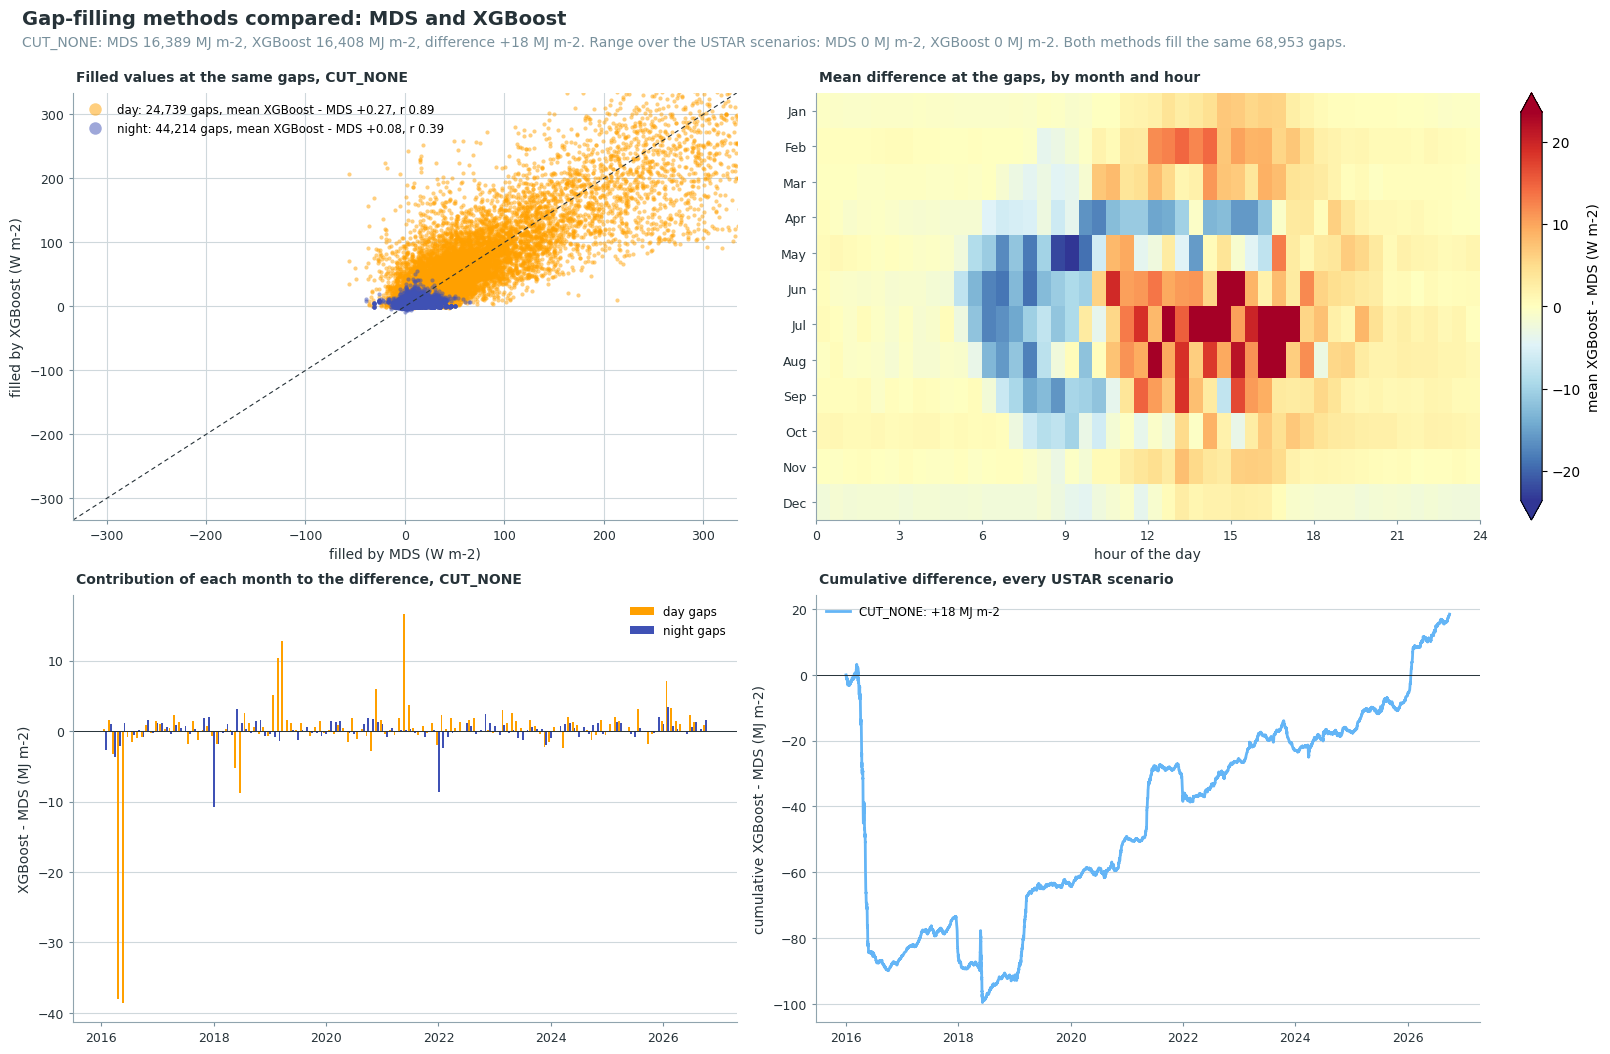

In [46]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario=USTAR_SCENARIO, methods=('mds', 'xgb'),
                               gain=W_TO_MJ, units='MJ m-2', flux_units=FLUX_UNITS);

## Step 11: evapotranspiration

ET is LE divided by the latent heat of vaporization, which depends on air temperature
(`et_from_le` with `TA_F`, after the R package bigleaf). The ET column of each gap-filling method
holds mm per half-hour and sums directly to totals. The input column `ET` is the EddyPro rate of
the measured records only.

### 📋 Table: ET columns

In [47]:
_ta = data.full_df[TA_F].reindex(data.fpc_df.index)
assert _ta.notna().all(), f"{TA_F} has gaps"
ET_COLS = {}  # {method: ET column}
_et = {}
for _method, _cols in data.gapfilled_cols().items():
    _le = data.fpc_df[_cols[USTAR_SCENARIO]]
    assert _le.name.startswith(FLUXCOL), _le.name
    _name = 'ET' + _le.name[len(FLUXCOL):]
    _et[_name] = et_from_le(le=_le, ta=_ta) * HOURS_PER_RECORD  # mm h-1 -> mm per half-hour
    ET_COLS[_method] = _name
ET_EXPORT = pd.DataFrame(_et)
assert ET_EXPORT.notna().all().all(), "a gap-filled record has no ET"

_names = {'mds': 'MDS', 'xgb': 'XGBoost', 'rf': 'random forest'}
display(pd.DataFrame({
    'from LE column': [data.gapfilled_cols()[_k][USTAR_SCENARIO] for _k in ET_COLS],
    'method': [_names.get(_k, _k) for _k in ET_COLS],
    'units': 'mm per half-hour',
    'records': [int(ET_EXPORT[_c].count()) for _c in ET_COLS.values()],
    'mean (mm d-1)': [round(float(ET_EXPORT[_c].mean()) * 48, 2) for _c in ET_COLS.values()],
}, index=pd.Index(list(ET_COLS.values()), name='ET column')))

,from LE column,method,units,records,mean (mm d-1)
ET column,,,,,
ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS,LE_L3.1_L3.3_CUT_NONE_QCF_gfMDS,MDS,mm per half-hour,188448,1.7
ET_L3.1_L3.3_CUT_NONE_QCF_gfXG,LE_L3.1_L3.3_CUT_NONE_QCF_gfXG,XGBoost,mm per half-hour,188448,1.7


### 📋 Table: annual sums of ET

Annual sums in mm for each gap-filling method, and their difference. An incomplete last year is a
partial sum.

In [48]:
ANNUAL_ET = ET_EXPORT.groupby(ET_EXPORT.index.year).sum()
ANNUAL_ET.columns = [_names.get(_k, _k) for _k in ET_COLS]
ANNUAL_ET.index.name = 'year'
if {'XGBoost', 'MDS'} <= set(ANNUAL_ET.columns):
    ANNUAL_ET['XGBoost - MDS'] = ANNUAL_ET['XGBoost'] - ANNUAL_ET['MDS']
print("Annual sums of ET (mm)")
display(ANNUAL_ET.round(1))

Annual sums of ET (mm)


,MDS,XGBoost,XGBoost - MDS
year,,,
2016,645.3,610.7,-34.6
2017,617.0,617.0,0.0
2018,575.1,572.2,-2.9
2019,583.7,595.2,11.5
2020,596.3,602.2,6.0
2021,543.3,548.0,4.7
2022,617.8,622.6,4.8
2023,641.8,642.9,1.2
2024,627.8,630.1,2.3


### 📊 Plot: annual sums of ET

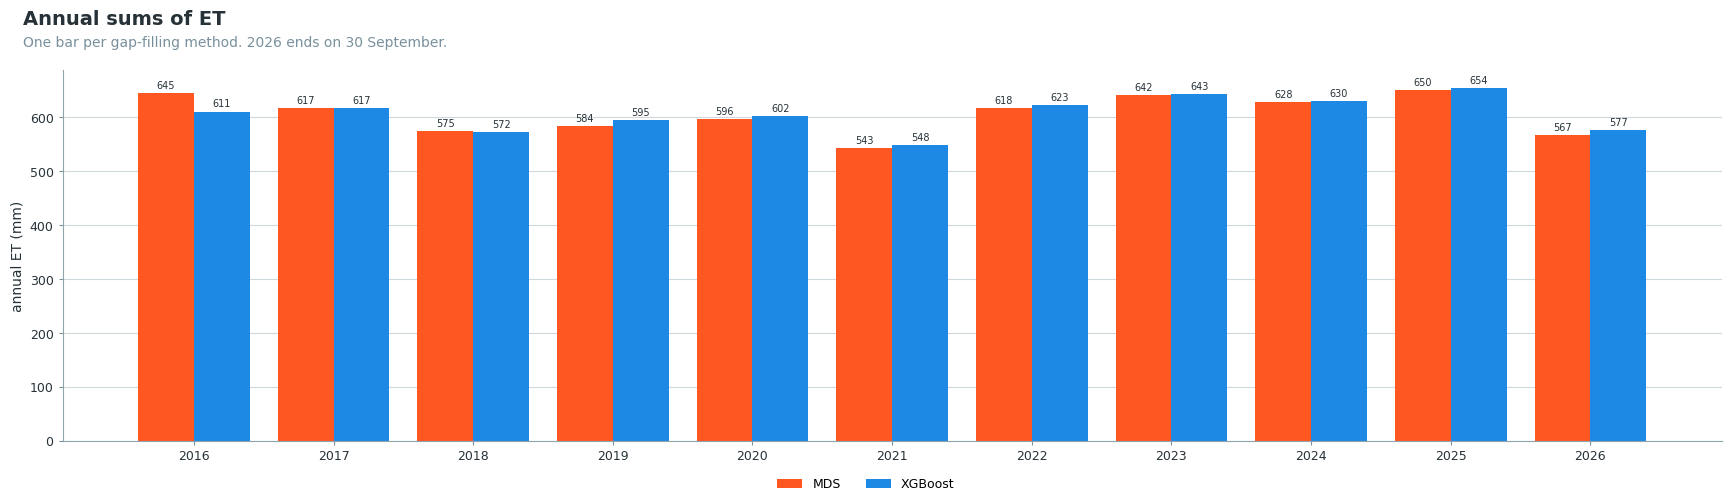

In [49]:
_colors = {_names.get(_k, _k): _v[1] for _k, _v in cp.METHOD_COLORS.items()}  # hue of each method
_methods = [_names.get(_k, _k) for _k in ET_COLS]
_years = ANNUAL_ET.index
_width = 0.8 / len(_methods)
_end = ET_EXPORT.index[-1]
fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(_years) + 4), 5), layout='constrained')
for _i, _method in enumerate(_methods):
    _x = np.arange(len(_years)) + (_i - (len(_methods) - 1) / 2) * _width
    ax.bar(_x, ANNUAL_ET[_method], _width, color=_colors.get(_method, cp.KEPT), label=_method)
    for _xi, _v in zip(_x, ANNUAL_ET[_method]):
        ax.annotate(f'{_v:.0f}', (_xi, _v), ha='center', va='bottom', fontsize=7, color=cp.INK,
                    xytext=(0, 2), textcoords='offset points')
ax.set_xticks(np.arange(len(_years)), _years)
ax.set_ylabel('annual ET (mm)')
cp.style_axes(ax)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center', frameon=False,
           ncol=len(_methods), fontsize=9)
cp.figure_title(fig, 'Annual sums of ET',
                "One bar per gap-filling method."
                + (f" {_end.year} ends on {_end:%d %B}." if (_end.month, _end.day) != (12, 31)
                   else ""))
plt.show()

## 💾 Step 12: export

The output file holds only what this notebook adds: every column the chain created and the ET
columns of Step 11. The input columns stay unchanged in the input file; the merge into the fullset
joins the outputs of the flux notebooks with it on the timestamp.

In [50]:
# Only the new columns: the input columns are in the input file and are added back in the merge.
_all = data.merged_df().join(ET_EXPORT)
out_df = _all[[c for c in _all.columns if c not in df.columns]]
assert out_df.index.equals(df.index), "the output timestamps differ from the input"
assert set(ET_EXPORT.columns) <= set(out_df.columns), "ET columns missing from the output"
print(f"ET columns in the output: {list(ET_EXPORT.columns)}")
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns (input columns left out: "
      f"{_all.shape[1] - out_df.shape[1]})")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 40 (L2: 12, L3.1: 7, L3.2: 10, L3.3: 7, L4.1:
4)

> No variables in the input data were overwritten, only new variables added.

ET columns in the output: ['ET_L3.1_L3.3_CUT_NONE_QCF_gfMDS', 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG']
188,448 records x 45 columns (input columns left out: 347)


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_POST-PROC
ESSING_CHAIN\IRGA72\25_FPPC_IRGA72_LE_2016-2026.09.parquet (0.566 seconds).

***

# End of notebook.

In [51]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-29 21:06:19
Finished: 2026-10-29 21:28:48
Runtime:  00:22:28 (hh:mm:ss)
